--- DATA PREPARATION ---
Loading real data from creditcard.csv...
Real data loaded: 284807 transactions.

--- APPLYING OVERSAMPLING ---
Original Training Counts: Normal=227451, Fraud=394
Balanced Training Counts: 454902 transactions (50% Fraud / 50% Normal)

--- STARTING TRAINING (Balanced Data) ---
Epoch 1/50 | Train Loss: 0.1909 | Val Loss: 0.0725
Epoch 2/50 | Train Loss: 0.0918 | Val Loss: 0.0432
Epoch 3/50 | Train Loss: 0.0648 | Val Loss: 0.0355
Epoch 4/50 | Train Loss: 0.0505 | Val Loss: 0.0324
Epoch 5/50 | Train Loss: 0.0408 | Val Loss: 0.0268
Epoch 6/50 | Train Loss: 0.0342 | Val Loss: 0.0241
Epoch 7/50 | Train Loss: 0.0297 | Val Loss: 0.0186
Epoch 8/50 | Train Loss: 0.0266 | Val Loss: 0.0206
Epoch 9/50 | Train Loss: 0.0240 | Val Loss: 0.0186
Epoch 10/50 | Train Loss: 0.0230 | Val Loss: 0.0169
Epoch 11/50 | Train Loss: 0.0217 | Val Loss: 0.0173
Epoch 12/50 | Train Loss: 0.0215 | Val Loss: 0.0179
Epoch 13/50 | Train Loss: 0.0202 | Val Loss: 0.0179
Epoch 14/50 | Train Loss: 0.0192

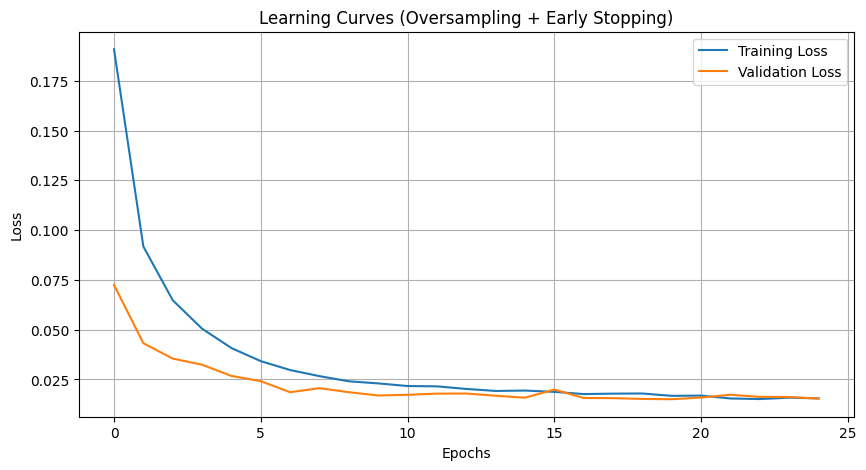


--- FINAL EVALUATION ---

  RESULTS AT THRESHOLD 0.5
Confusion Matrix:
[[56741   123]
 [   12    86]]
Detected Frauds (TP): 86 / 98
False Alarms (FP):    123

  RESULTS AT THRESHOLD 0.9
Confusion Matrix:
[[56804    60]
 [   13    85]]
Detected Frauds (TP): 85 / 98
False Alarms (FP):    60

  RESULTS AT THRESHOLD 0.99
Confusion Matrix:
[[56831    33]
 [   15    83]]
Detected Frauds (TP): 83 / 98
False Alarms (FP):    33


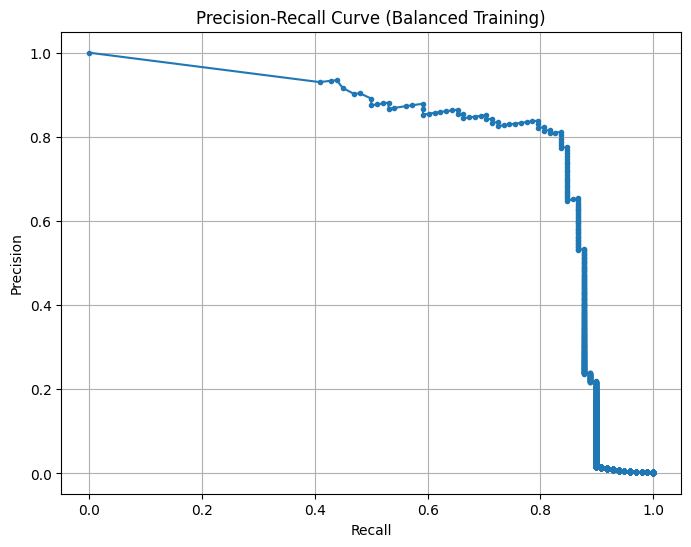

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import copy

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# ==========================================
# 1. DATA GENERATION & PREPROCESSING
# ==========================================
print("--- DATA PREPARATION ---")

data_file = 'creditcard.csv'

if os.path.exists(data_file):
    print(f"Loading real data from {data_file}...")
    df = pd.read_csv(data_file)

    # CLEANING STEP: Remove rows with missing values
    if df.isnull().values.any():
        df = df.dropna()
        print("Dropped rows containing missing values.")

    X = df.drop('Class', axis=1).values
    y = df['Class'].values
    print(f"Real data loaded: {X.shape[0]} transactions.")

else:
    print(f"File '{data_file}' not found. Generating synthetic data...")
    X, y = make_classification(n_samples=50000, n_features=30, n_informative=24,
                               n_classes=2, weights=[0.99, 0.01], random_state=42)

# Split into Training and Testing
# We use stratify to ensure the tiny amount of fraud is split evenly
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ---------------------------------------------------------
# OVERSAMPLING TECHNIQUE (The Fix)
# Instead of using class weights, we balance the training data
# by duplicating the fraud examples until they match the normal count.
# ---------------------------------------------------------
print("\n--- APPLYING OVERSAMPLING ---")
# Identify indices
train_fraud_indices = np.where(y_train == 1)[0]
train_normal_indices = np.where(y_train == 0)[0]

print(f"Original Training Counts: Normal={len(train_normal_indices)}, Fraud={len(train_fraud_indices)}")

# Randomly sample fraud indices with replacement to match normal count
# This creates a 50/50 balanced dataset for training
oversampled_fraud_indices = np.random.choice(train_fraud_indices, size=len(train_normal_indices), replace=True)

# Combine indices
balanced_indices = np.concatenate([train_normal_indices, oversampled_fraud_indices])
np.random.shuffle(balanced_indices) # Shuffle to mix them up

X_train_balanced = X_train[balanced_indices]
y_train_balanced = y_train[balanced_indices]

print(f"Balanced Training Counts: {len(y_train_balanced)} transactions (50% Fraud / 50% Normal)")
# Note: We DO NOT touch X_test. We must validate on the REAL imbalanced distribution.

# Standardization
scaler = StandardScaler()
# Fit only on the training data (to prevent data leakage)
X_train_balanced = scaler.fit_transform(X_train_balanced)
X_test = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_balanced, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_balanced, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

# Mini-Batch Loader
BATCH_SIZE = 512 # Increased batch size for stable gradients
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

# ==========================================
# 2. DEFINE ARCHITECTURE
# ==========================================
class FraudDetectorMLP(nn.Module):
    def __init__(self, input_dim):
        super(FraudDetectorMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.4), # Increased Dropout to fight overfitting

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

input_features = X_train.shape[1]
model = FraudDetectorMLP(input_features)

# ==========================================
# 3. LOSS & OPTIMIZER
# ==========================================
# Since we balanced the dataset manually, we do NOT need pos_weight anymore!
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005) # Lower LR for stability

# ==========================================
# 4. TRAINING WITH EARLY STOPPING
# ==========================================
print("\n--- STARTING TRAINING (Balanced Data) ---")
EPOCHS = 50
train_losses = []
val_losses = []

best_val_loss = float('inf')
patience = 5 # Stop if no improvement for 5 epochs
patience_counter = 0
best_model_weights = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0

    for X_batch, y_batch in train_loader:
        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)

    # Validation
    model.eval()
    with torch.no_grad():
        val_logits = model(X_test_tensor)
        val_loss = criterion(val_logits, y_test_tensor)

    train_losses.append(avg_train_loss)
    val_losses.append(val_loss.item())

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss.item():.4f}")

    # Early Stopping Logic
    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_model_weights = copy.deepcopy(model.state_dict())
        patience_counter = 0 # Reset counter
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early Stopping triggered at Epoch {epoch+1}!")
            break

# Load best model
model.load_state_dict(best_model_weights)

# ==========================================
# 5. VISUALIZATION
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Learning Curves (Oversampling + Early Stopping)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# 6. EVALUATION
# ==========================================
print("\n--- FINAL EVALUATION ---")
model.eval()
with torch.no_grad():
    final_logits = model(X_test_tensor)
    final_probs = torch.sigmoid(final_logits)

    y_true_np = y_test_tensor.numpy()
    y_probs_np = final_probs.numpy()

# Note: Since we trained on balanced data (50% fraud), the model output
# will be much higher on average. The default 0.5 threshold is usually very accurate now.
thresholds = [0.5, 0.9, 0.99]

for thresh in thresholds:
    print(f"\n=============================")
    print(f"  RESULTS AT THRESHOLD {thresh}")
    print(f"=============================")
    final_preds = (y_probs_np > thresh).astype(float)

    cm = confusion_matrix(y_true_np, final_preds)
    print(f"Confusion Matrix:\n{cm}")
    print(f"Detected Frauds (TP): {cm[1,1]} / {cm[1,0]+cm[1,1]}")
    print(f"False Alarms (FP):    {cm[0,1]}")

precision, recall, _ = precision_recall_curve(y_true_np, y_probs_np)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', label='MLP')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Balanced Training)')
plt.grid(True)
plt.show()